# PathMNIST: MedMamba vs ResNet18 / DenseNet / ViT / Swin  


**Model (MedMamba)**
* Uses the real MedMamba **SS-Conv-SSM** block: channels are split in half, one half goes through a *selective state-space (SS2D)* branch, the other through a *conv* branch, then channel-shuffle + residual.
* 4-direction cross-scan (row, column, and both reversed) instead of one flattened 1-D scan.
* Hierarchical 3-stage design (14x14 -> 7x7 -> 4x4) instead of a single 7x7 stage, so fine texture is no longer thrown away by a 4x4 patch embed.
* Proper input-dependent `dt`, `B`, `C` and a 16-dim state. Computed **in parallel** (matrix form of the scan) instead of a Python `for` loop over tokens.
* Fixed the residual/normalisation problems in the old block (no identity path around the conv, BatchNorm head that made validation jump around).

**Training recipe (applied to *every* model, so the comparison stays fair)**
* Data lives on the GPU; augmentation (flips, 90-degree rotations, shifts, colour/stain jitter) runs on the GPU. No DataLoader workers.
* AdamW + warm-up/cosine (OneCycle), label smoothing, gradient clipping, EMA weights, fp16 autocast.
* Test-time augmentation (8 flips/rotations).


In [1]:
!pip install -q medmnist

In [2]:
import os, time, copy, math, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from torchvision.models.swin_transformer import SwinTransformer
from medmnist import PathMNIST, INFO

from sklearn.model_selection import train_test_split
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

warnings.filterwarnings("ignore", message=".*lr_scheduler.step.*")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
torch.backends.cudnn.benchmark = True

print("Device:", device)
if use_amp:
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU found. Runtime > Change runtime type > T4 GPU.")

Device: cuda
GPU: Tesla T4


In [3]:
# ----------------------------- configuration -----------------------------
DATA_FLAG         = "pathmnist"
NUM_CLASSES       = 9

TRAIN_SUBSET_SIZE = 5000     # same stratified subset as before. 10000 -> more accuracy, ~2x time
EPOCHS            = 25       # same for every model. Lower to 15-20 if you need it even faster
BATCH_SIZE        = 128
WEIGHT_DECAY      = 0.05
LABEL_SMOOTHING   = 0.1
EMA_DECAY         = 0.99
USE_TTA           = True     # 8-way flip/rotate test-time augmentation (applied to all models)
PRINT_EVERY       = 3

PREV_MEDMAMBA_TEST_ACC = 0.6769   # MedMamba-Tiny from your original run, for the before/after line

OUTPUT_DIR = "/content/pathmnist_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

class_names = [INFO[DATA_FLAG]["label"][str(i)] for i in range(NUM_CLASSES)]
print(class_names)

['adipose', 'background', 'debris', 'lymphocytes', 'mucus', 'smooth muscle', 'normal colon mucosa', 'cancer-associated stroma', 'colorectal adenocarcinoma epithelium']


## Data (kept on the GPU)

In [4]:
train_raw = PathMNIST(split="train", download=True)
val_raw   = PathMNIST(split="val",   download=True)
test_raw  = PathMNIST(split="test",  download=True)

train_labels_all = np.asarray(train_raw.labels).reshape(-1)
subset_idx, _ = train_test_split(
    np.arange(len(train_labels_all)),
    train_size=TRAIN_SUBSET_SIZE,
    stratify=train_labels_all,
    random_state=SEED,
)

def to_gpu(ds, idx=None):
    imgs = np.asarray(ds.imgs)
    labels = np.asarray(ds.labels).reshape(-1).astype(np.int64)
    if idx is not None:
        imgs, labels = imgs[idx], labels[idx]
    X = torch.from_numpy(np.ascontiguousarray(imgs)).permute(0, 3, 1, 2).contiguous().to(device)  # uint8 NCHW
    y = torch.from_numpy(labels).to(device)
    return X, y

X_train, y_train = to_gpu(train_raw, subset_idx)
X_val,   y_val   = to_gpu(val_raw)
X_test,  y_test  = to_gpu(test_raw)

print("Train:", tuple(X_train.shape), "| Val:", tuple(X_val.shape), "| Test:", tuple(X_test.shape))
print("Train class counts:", torch.bincount(y_train, minlength=NUM_CLASSES).tolist())

100%|██████████| 206M/206M [02:20<00:00, 1.46MB/s]


Train: (5000, 3, 28, 28) | Val: (10004, 3, 28, 28) | Test: (7180, 3, 28, 28)
Train class counts: [520, 528, 576, 578, 445, 677, 438, 522, 716]


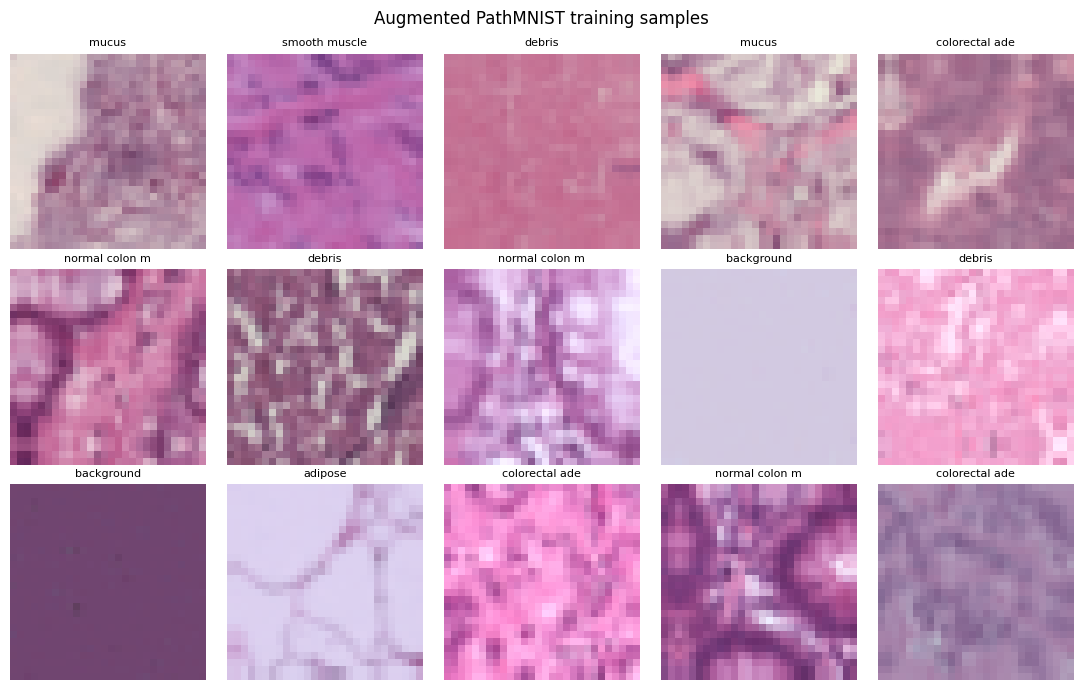

In [5]:
def normalize(x01):
    return (x01 - 0.5) / 0.5

def prep_eval(x_uint8):
    return normalize(x_uint8.float().div(255.0))

def augment(x_uint8):
    """GPU augmentation. Histology has no canonical orientation, so the full
    flip/rotate group is safe. Colour jitter imitates stain / scanner variation
    (PathMNIST test images come from a different patient cohort than training)."""
    x = x_uint8.float().div(255.0)
    B, dev = x.size(0), x.device
    m = lambda b: b.view(-1, 1, 1, 1)

    # random element of the dihedral group: flips + transpose
    x = torch.where(m(torch.rand(B, device=dev) < 0.5), x.flip(3), x)
    x = torch.where(m(torch.rand(B, device=dev) < 0.5), x.flip(2), x)
    x = torch.where(m(torch.rand(B, device=dev) < 0.5), x.transpose(2, 3), x)

    # mild random shift / zoom (70% of samples; the rest stay pixel-exact)
    use = (torch.rand(B, device=dev) < 0.7).float()
    s  = 1 + (torch.rand(B, device=dev) * 2 - 1) * 0.10 * use
    tx = (torch.rand(B, device=dev) * 2 - 1) * 0.15 * use
    ty = (torch.rand(B, device=dev) * 2 - 1) * 0.15 * use
    theta = torch.zeros(B, 2, 3, device=dev)
    theta[:, 0, 0] = 1 / s
    theta[:, 1, 1] = 1 / s
    theta[:, 0, 2] = tx
    theta[:, 1, 2] = ty
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)

    # colour / stain jitter
    r = lambda *shape: torch.rand(*shape, device=dev) * 2 - 1
    x = x * (1 + r(B, 1, 1, 1) * 0.15)                                   # brightness
    mu = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - mu) * (1 + r(B, 1, 1, 1) * 0.20) + mu                       # contrast
    gray = x.mean(dim=1, keepdim=True)
    x = (x - gray) * (1 + r(B, 1, 1, 1) * 0.25) + gray                   # saturation
    x = x * (1 + r(B, 3, 1, 1) * 0.08) + r(B, 3, 1, 1) * 0.04            # per-channel gain / shift
    return normalize(x.clamp(0, 1))

# quick look at augmented training images
idx = torch.arange(15, device=device)
imgs = augment(X_train[idx]).cpu()
fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow((imgs[i].permute(1, 2, 0) * 0.5 + 0.5).clamp(0, 1).numpy())
    ax.set_title(class_names[y_train[i].item()][:14], fontsize=8)
    ax.axis("off")
plt.suptitle("Augmented PathMNIST training samples")
plt.tight_layout(); plt.show()

## Models

### MedMamba
SS-Conv-SSM blocks (as in the MedMamba paper) with a 4-direction selective state-space layer.  
The scan `h_t = a_t * h_{t-1} + B_t * (dt_t * u_t)`, `y_t = C_t . h_t` is evaluated in its equivalent **parallel matrix form**
(`y = (decay-mask * C B^T) @ (dt * u)`), which is exact and runs on the GPU without a Python loop. Token counts here are small (196 / 49 / 16), so this is cheap.

In [6]:
class DropPath(nn.Module):
    def __init__(self, p=0.0):
        super().__init__()
        self.p = p
    def forward(self, x):
        if self.p == 0.0 or not self.training:
            return x
        keep = 1.0 - self.p
        mask = x.new_empty((x.shape[0],) + (1,) * (x.ndim - 1)).bernoulli_(keep)
        return x * mask / keep


class SS2D(nn.Module):
    """Cross-scan selective state-space layer. Input/output: [B, H, W, C] (channels last)."""
    def __init__(self, d_model, d_state=16, expand=2, heads=2, dt_min=0.01, dt_max=0.2):
        super().__init__()
        self.d_inner = d_model * expand
        self.d_state = d_state
        self.heads = heads
        assert self.d_inner % heads == 0
        K = 4  # row, column, row-reversed, column-reversed

        self.in_proj = nn.Linear(d_model, self.d_inner * 2, bias=False)
        self.dwconv = nn.Conv2d(self.d_inner, self.d_inner, 3, padding=1, groups=self.d_inner)

        # per-direction projection of the token to (dt, B, C)
        self.x_proj_weight = nn.Parameter(torch.empty(K, heads + 2 * d_state, self.d_inner))
        bound = 1.0 / math.sqrt(self.d_inner)
        nn.init.uniform_(self.x_proj_weight, -bound, bound)

        # dt bias initialised so softplus(dt_bias) lies in [dt_min, dt_max]
        dt = torch.exp(torch.rand(K, heads) * (math.log(dt_max) - math.log(dt_min)) + math.log(dt_min))
        self.dt_bias = nn.Parameter(dt + torch.log(-torch.expm1(-dt)))
        self.A_log = nn.Parameter(torch.log(torch.empty(K, heads).uniform_(1.0, 16.0)))
        self.D_skip = nn.Parameter(torch.ones(K, self.d_inner))

        self.out_norm = nn.LayerNorm(self.d_inner)
        self.out_proj = nn.Linear(self.d_inner, d_model, bias=False)

    def _ssd_scan(self, xs):
        # xs: [B, K, D, L]
        B, K, D, L = xs.shape
        Hh, N = self.heads, self.d_state
        P = D // Hh

        proj = torch.einsum("bkdl,kcd->bkcl", xs, self.x_proj_weight)       # [B,K,Hh+2N,L]
        dt_raw, Bm, Cm = torch.split(proj, [Hh, N, N], dim=2)
        dt = F.softplus(dt_raw.float() + self.dt_bias[None, :, :, None])    # [B,K,Hh,L]
        A = -torch.exp(self.A_log.float())                                  # [K,Hh]
        c = torch.cumsum(dt * A[None, :, :, None], dim=-1)                  # cumulative log-decay (fp32)

        seg = c.unsqueeze(-1) - c.unsqueeze(-2)                             # c_t - c_s  [B,K,Hh,L,L]
        mask = torch.tril(torch.ones(L, L, device=xs.device)).bool()
        decay = torch.exp(seg.masked_fill(~mask, float("-inf")))            # causal, always <= 1

        G = torch.einsum("bknt,bkns->bkts", Cm, Bm)                         # C_t . B_s   [B,K,L,L]
        M = decay.to(G.dtype) * G.unsqueeze(2)                              # [B,K,Hh,L,L]
        v = (xs.reshape(B, K, Hh, P, L) * dt.unsqueeze(3)).to(M.dtype)      # dt_s * u_s
        y = torch.matmul(M, v.transpose(-1, -2))                            # [B,K,Hh,L,P]
        y = y.transpose(-1, -2).reshape(B, K, D, L)
        return y + xs * self.D_skip[None, :, :, None]

    def _cross_scan(self, x):
        # x: [B, D, H, W]
        B, D, H, W = x.shape
        L = H * W
        x_hw = x.flatten(2)
        x_wh = x.transpose(2, 3).flatten(2)
        xs = torch.stack([x_hw, x_wh], dim=1)
        xs = torch.cat([xs, xs.flip(-1)], dim=1)                            # [B,4,D,L]
        ys = self._ssd_scan(xs)
        y_hw = ys[:, 0] + ys[:, 2].flip(-1)
        y_wh = ys[:, 1] + ys[:, 3].flip(-1)
        y_wh = y_wh.reshape(B, D, W, H).transpose(2, 3).reshape(B, D, L)
        return (y_hw + y_wh).reshape(B, D, H, W)

    def forward(self, x):
        xz = self.in_proj(x)
        x_in, z = xz.chunk(2, dim=-1)
        x_in = x_in.permute(0, 3, 1, 2).contiguous()
        x_in = F.silu(self.dwconv(x_in))
        y = self._cross_scan(x_in).permute(0, 2, 3, 1)
        y = self.out_norm(y) * F.silu(z)
        return self.out_proj(y)


def channel_shuffle(x, groups=2):
    B, H, W, C = x.shape
    return x.reshape(B, H, W, groups, C // groups).transpose(3, 4).reshape(B, H, W, C)


class SSConvSSMBlock(nn.Module):
    """MedMamba SS-Conv-SSM block: half the channels -> SS2D, half -> convs, shuffle, residual."""
    def __init__(self, dim, d_state=16, heads=2, drop_path=0.0):
        super().__init__()
        half = dim // 2
        self.ln = nn.LayerNorm(half)
        self.ssm = SS2D(half, d_state=d_state, heads=heads)
        self.drop_path = DropPath(drop_path)
        self.conv = nn.Sequential(
            nn.BatchNorm2d(half),
            nn.Conv2d(half, half, 3, 1, 1, bias=False), nn.BatchNorm2d(half), nn.ReLU(inplace=True),
            nn.Conv2d(half, half, 3, 1, 1, bias=False), nn.BatchNorm2d(half), nn.ReLU(inplace=True),
            nn.Conv2d(half, half, 1),
        )

    def forward(self, x):                                   # x: [B,H,W,C]
        left, right = x.chunk(2, dim=-1)
        right = right + self.drop_path(self.ssm(self.ln(right)))
        left = self.conv(left.permute(0, 3, 1, 2).contiguous()).permute(0, 2, 3, 1)
        out = channel_shuffle(torch.cat([left, right], dim=-1))
        return out + x


class MedMambaPlus(nn.Module):
    def __init__(self, num_classes=9, dims=(64, 128, 256), depths=(2, 4, 2),
                 d_state=16, heads=2, drop_path=0.1, head_drop=0.1):
        super().__init__()
        self.stem = nn.Sequential(                           # 28x28 -> 14x14
            nn.Conv2d(3, dims[0] // 2, 3, 1, 1, bias=False), nn.BatchNorm2d(dims[0] // 2), nn.GELU(),
            nn.Conv2d(dims[0] // 2, dims[0], 3, 2, 1, bias=False), nn.BatchNorm2d(dims[0]),
        )
        dpr = torch.linspace(0, drop_path, sum(depths)).tolist()
        self.stages, self.downs = nn.ModuleList(), nn.ModuleList()
        k = 0
        for s, (dim, depth) in enumerate(zip(dims, depths)):
            self.stages.append(nn.ModuleList(
                [SSConvSSMBlock(dim, d_state, heads, dpr[k + j]) for j in range(depth)]))
            k += depth
            if s < len(dims) - 1:                            # 14->7->4
                self.downs.append(nn.Sequential(
                    nn.Conv2d(dim, dims[s + 1], 3, 2, 1, bias=False), nn.BatchNorm2d(dims[s + 1])))
        self.norm = nn.LayerNorm(dims[-1])
        self.drop = nn.Dropout(head_drop)
        self.head = nn.Linear(dims[-1], num_classes)

    def forward(self, x):
        x = self.stem(x)
        for s, blocks in enumerate(self.stages):
            x = x.permute(0, 2, 3, 1)
            for blk in blocks:
                x = blk(x)
            x = x.permute(0, 3, 1, 2)
            if s < len(self.downs):
                x = self.downs[s](x)
        x = x.mean(dim=(2, 3))
        return self.head(self.drop(self.norm(x)))

### Baselines: ResNet18, ViT-Tiny, DenseNet and Swin

In [7]:
def build_resnet18(num_classes=9):
    model = models.resnet18(weights=None)
    model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    model.maxpool = nn.Identity()
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


class ViTTiny(nn.Module):
    def __init__(self, num_classes=9, image_size=28, patch_size=4, dim=192, depth=4, heads=3):
        super().__init__()
        assert image_size % patch_size == 0
        num_patches = (image_size // patch_size) ** 2
        self.patch_embed = nn.Conv2d(3, dim, kernel_size=patch_size, stride=patch_size)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, dim))
        layer = nn.TransformerEncoderLayer(d_model=dim, nhead=heads, dim_feedforward=dim * 4,
                                           dropout=0.1, activation="gelu",
                                           batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, num_classes)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def forward(self, x):
        B = x.shape[0]
        x = self.patch_embed(x).flatten(2).transpose(1, 2)
        x = torch.cat([self.cls_token.expand(B, -1, -1), x], dim=1) + self.pos_embed
        x = self.norm(self.encoder(x))
        return self.head(x[:, 0])


def build_densenet(num_classes=9):
    """Compact DenseNet-BC for 28x28 inputs (3x3 stride-1 stem, no stem max-pool).
    For the full DenseNet-121 use growth_rate=32, block_config=(6,12,24,16), num_init_features=64 (~2x slower)."""
    init = 48
    model = models.DenseNet(growth_rate=24, block_config=(4, 6, 8, 6), num_init_features=init,
                            bn_size=4, drop_rate=0.0, num_classes=num_classes)
    model.features.conv0 = nn.Conv2d(3, init, kernel_size=3, stride=1, padding=1, bias=False)
    model.features.pool0 = nn.Identity()
    return model


def build_swin(num_classes=9):
    """Swin for 28x28: 2x2 patches -> 14x14 tokens, 7x7 windows (shifted), 2 stages (14x14 -> 7x7)."""
    return SwinTransformer(patch_size=[2, 2], embed_dim=64, depths=[2, 6], num_heads=[4, 8],
                           window_size=[7, 7], stochastic_depth_prob=0.1, num_classes=num_classes)


# name -> (builder, peak learning rate)
MODEL_SPECS = {
    "MedMamba": (lambda: MedMambaPlus(NUM_CLASSES), 2e-3),
    "ResNet18":      (lambda: build_resnet18(NUM_CLASSES), 2e-3),
    "DenseNet":      (lambda: build_densenet(NUM_CLASSES), 2e-3),
    "ViT-Tiny":      (lambda: ViTTiny(NUM_CLASSES), 1e-3),
    "Swin-Tiny":     (lambda: build_swin(NUM_CLASSES), 1e-3),
}

# sanity check: forward pass + parameter count
for name, (build, _) in MODEL_SPECS.items():
    m = build().to(device).eval()
    with torch.no_grad():
        out = m(torch.randn(4, 3, 28, 28, device=device))
    n_params = sum(p.numel() for p in m.parameters())
    print(f"{name:14s} {n_params/1e6:6.2f}M params | output {tuple(out.shape)}")
    del m

MedMamba         1.85M params | output (4, 9)
ResNet18        11.17M params | output (4, 9)
DenseNet         0.97M params | output (4, 9)
ViT-Tiny         1.80M params | output (4, 9)
Swin-Tiny        1.33M params | output (4, 9)


## Training utilities

In [8]:
class ModelEMA:
    """Exponential moving average of weights (and BN statistics). Evaluated instead of the raw model."""
    def __init__(self, model, decay=0.99):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay, self.updates = decay, 0

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        d = min(self.decay, (1 + self.updates) / (10 + self.updates))
        src = model.state_dict()
        for k, v in self.module.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(src[k].detach(), alpha=1 - d)
            else:
                v.copy_(src[k])


NO_DECAY_KEYS = ("A_log", "D_skip", "dt_bias", "pos_embed", "cls_token", "relative_position_bias_table")

def make_optimizer(model, lr):
    decay, no_decay = [], []
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        (no_decay if p.ndim < 2 or any(k in n for k in NO_DECAY_KEYS) else decay).append(p)
    return torch.optim.AdamW(
        [{"params": decay, "weight_decay": WEIGHT_DECAY},
         {"params": no_decay, "weight_decay": 0.0}], lr=lr)


def dihedral(x, k):
    if k & 4: x = x.transpose(2, 3)
    if k & 1: x = x.flip(3)
    if k & 2: x = x.flip(2)
    return x.contiguous()


@torch.no_grad()
def predict_proba(model, X, tta=False, bs=500):
    model.eval()
    out = []
    for i in range(0, X.size(0), bs):
        xb = prep_eval(X[i:i + bs])
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            if tta:
                p = sum(F.softmax(model(dihedral(xb, k)).float(), dim=1) for k in range(8)) / 8
            else:
                p = F.softmax(model(xb).float(), dim=1)
        out.append(p)
    return torch.cat(out)


def evaluate(model, X, y, tta=False):
    p = predict_proba(model, X, tta)
    loss = F.nll_loss(torch.log(p.clamp_min(1e-8)), y).item()
    pred = p.argmax(1)
    acc = (pred == y).float().mean().item()
    return loss, acc, y.cpu().numpy(), pred.cpu().numpy()


def train_one_epoch(model, ema, optimizer, scheduler, scaler, criterion):
    model.train()
    N = X_train.size(0)
    perm = torch.randperm(N, device=device)
    loss_sum = torch.zeros((), device=device)
    correct = torch.zeros((), device=device)
    seen = 0
    for i in range(0, N - BATCH_SIZE + 1, BATCH_SIZE):          # drop the last partial batch
        idx = perm[i:i + BATCH_SIZE]
        xb, yb = augment(X_train[idx]), y_train[idx]
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            out = model(xb)
            loss = criterion(out, yb)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        ema.update(model)
        loss_sum += loss.detach() * yb.size(0)
        correct += (out.argmax(1) == yb).sum()
        seen += yb.size(0)
    return loss_sum.item() / seen, correct.item() / seen


def train_model(name, model, lr, epochs):
    model = model.to(device)
    ema = ModelEMA(model, EMA_DECAY)
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    optimizer = make_optimizer(model, lr)
    steps_per_epoch = X_train.size(0) // BATCH_SIZE
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr, total_steps=epochs * steps_per_epoch,
        pct_start=0.2, anneal_strategy="cos", div_factor=25, final_div_factor=1000)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val, best_state = -1.0, None
    t0 = time.time()

    for epoch in range(epochs):
        tr_loss, tr_acc = train_one_epoch(model, ema, optimizer, scheduler, scaler, criterion)
        va_loss, va_acc, _, _ = evaluate(ema.module, X_val, y_val)      # EMA weights

        for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
            history[k].append(v)

        if va_acc > best_val:
            best_val = va_acc
            best_state = copy.deepcopy(ema.module.state_dict())

        if (epoch + 1) % PRINT_EVERY == 0 or epoch == 0 or epoch + 1 == epochs:
            print(f"{name:14s} | ep {epoch+1:2d}/{epochs} | train loss {tr_loss:.3f} acc {tr_acc:.3f} "
                  f"| val loss {va_loss:.3f} acc {va_acc:.4f} | {time.time()-t0:5.0f}s")

    if use_amp:
        torch.cuda.synchronize()
    total_time = time.time() - t0
    ema.module.load_state_dict(best_state)
    torch.save(best_state, os.path.join(OUTPUT_DIR, f"{name}_best.pt"))
    print(f"{name} done in {total_time:.0f}s | best val acc {best_val:.4f}\n")
    return ema.module, history, total_time

## Train all models

In [9]:
trained_models, histories, training_times, param_counts = {}, {}, {}, {}

for name, (build, lr) in MODEL_SPECS.items():
    print("=" * 70); print("Training:", name); print("=" * 70)
    torch.manual_seed(SEED)
    model = build()
    param_counts[name] = sum(p.numel() for p in model.parameters())
    trained, hist, secs = train_model(name, model, lr, EPOCHS)
    trained_models[name], histories[name], training_times[name] = trained, hist, secs
    pd.DataFrame(hist).to_csv(os.path.join(OUTPUT_DIR, f"{name}_history.csv"), index=False)
    del model
    if use_amp:
        torch.cuda.empty_cache()

print(f"Total training time: {sum(training_times.values())/60:.1f} min")

Training: MedMamba
MedMamba       | ep  1/25 | train loss 1.847 acc 0.350 | val loss 1.690 acc 0.3696 |    17s
MedMamba       | ep  3/25 | train loss 1.589 acc 0.476 | val loss 1.166 acc 0.5859 |    31s
MedMamba       | ep  6/25 | train loss 1.209 acc 0.666 | val loss 0.793 acc 0.7249 |    53s
MedMamba       | ep  9/25 | train loss 1.071 acc 0.729 | val loss 0.650 acc 0.7784 |    76s
MedMamba       | ep 12/25 | train loss 0.937 acc 0.792 | val loss 0.523 acc 0.8294 |    99s
MedMamba       | ep 15/25 | train loss 0.880 acc 0.815 | val loss 0.474 acc 0.8514 |   122s
MedMamba       | ep 18/25 | train loss 0.819 acc 0.852 | val loss 0.436 acc 0.8675 |   145s
MedMamba       | ep 21/25 | train loss 0.779 acc 0.871 | val loss 0.415 acc 0.8756 |   169s
MedMamba       | ep 24/25 | train loss 0.768 acc 0.868 | val loss 0.404 acc 0.8799 |   193s
MedMamba       | ep 25/25 | train loss 0.763 acc 0.874 | val loss 0.403 acc 0.8807 |   201s
MedMamba done in 201s | best val acc 0.8807

Training: ResNet

## Test-set evaluation

In [10]:
results, test_predictions = [], {}

for name, model in trained_models.items():
    _, acc_plain, _, _ = evaluate(model, X_test, y_test, tta=False)
    test_loss, acc, y_true, y_pred = evaluate(model, X_test, y_test, tta=USE_TTA)

    test_predictions[name] = (y_true, y_pred)
    results.append({
        "Model": name,
        "Params (M)": param_counts[name] / 1e6,
        "Accuracy": acc,
        "Accuracy (no TTA)": acc_plain,
        "Test Loss": test_loss,
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Training Time (s)": training_times[name],
    })

results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False).reset_index(drop=True)
display(results_df.round(4))
results_df.to_csv(os.path.join(OUTPUT_DIR, "final_results.csv"), index=False)


,Model,Params (M),Accuracy,Accuracy (no TTA),Test Loss,Macro Precision,Macro Recall,Macro F1,Weighted F1,Training Time (s)
0,DenseNet,0.9715,0.8990,0.8923,0.3578,0.8567,0.8631,0.8563,0.8991,97.4918
1,ResNet18,11.1734,0.8971,0.8894,0.3530,0.8513,0.8577,0.8515,0.8968,75.1167
2,MedMamba,1.8521,0.8798,0.8724,0.4040,0.8340,0.8402,0.8328,0.8799,201.2183
3,Swin-Tiny,1.3347,0.8504,0.8455,0.4777,0.7961,0.7999,0.7930,0.8496,73.0631
4,ViT-Tiny,1.8008,0.8326,0.8085,0.5653,0.7864,0.7915,0.7833,0.8299,32.3613


## Plots

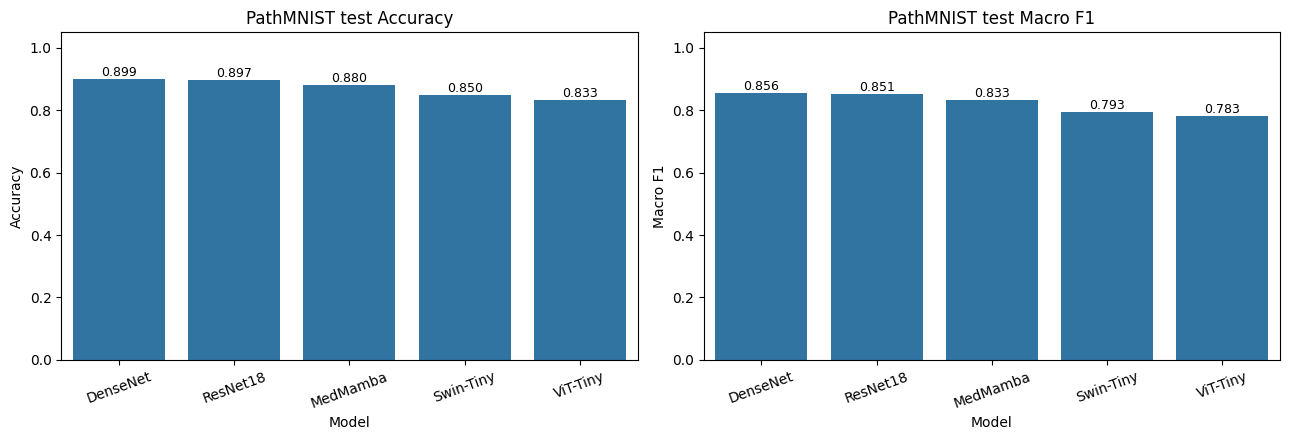

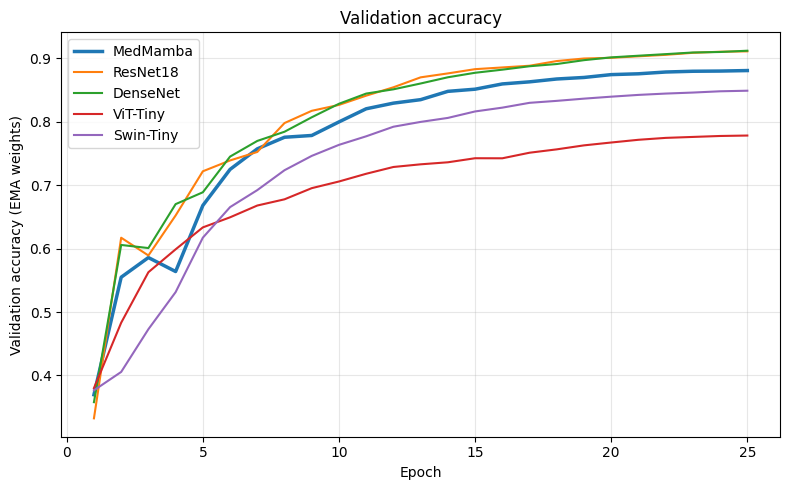

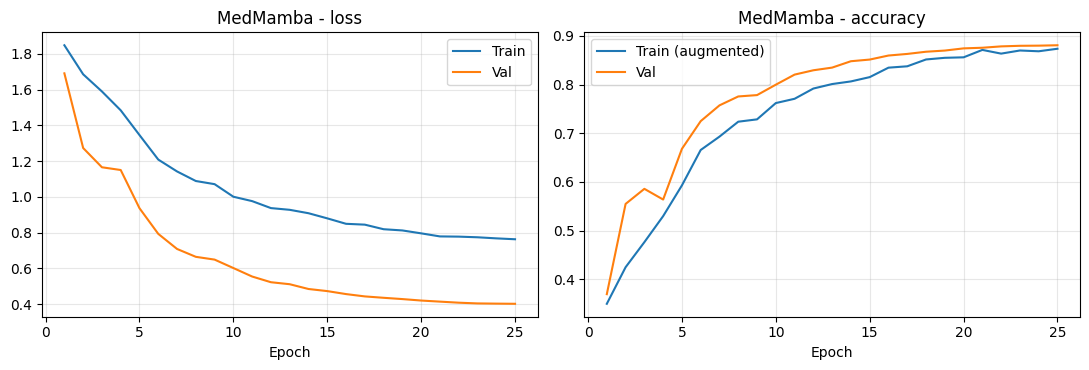

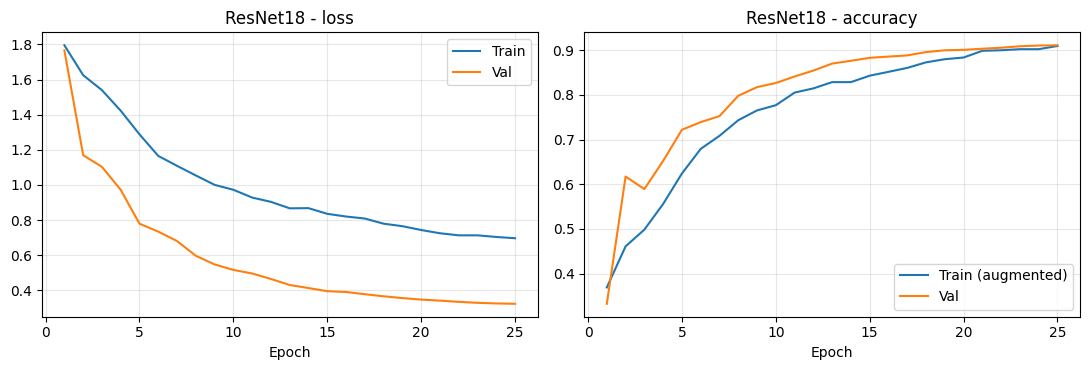

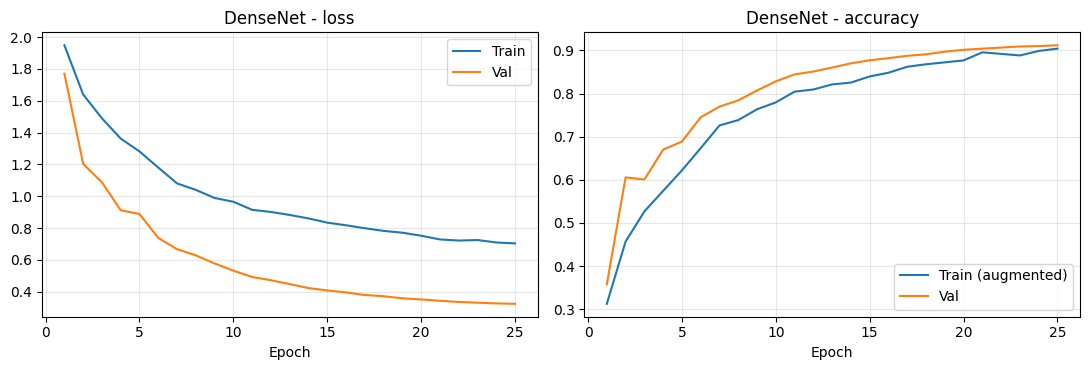

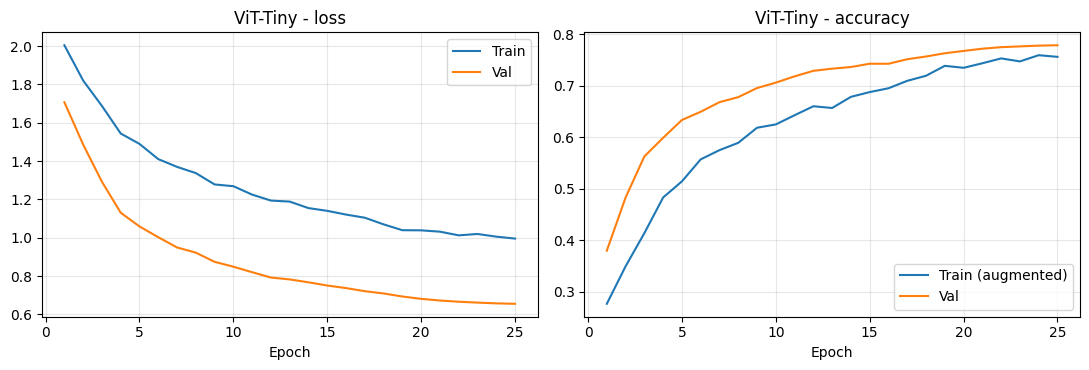

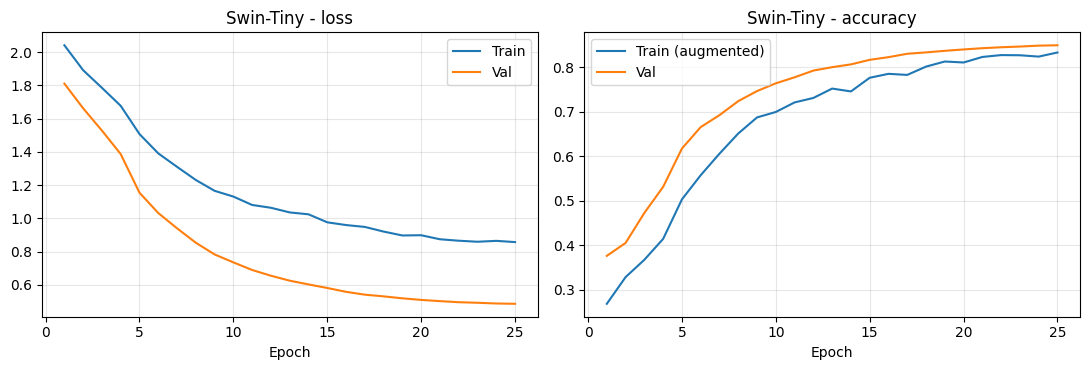

In [11]:
order = results_df["Model"].tolist()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, ["Accuracy", "Macro F1"]):
    sns.barplot(data=results_df, x="Model", y=col, order=order, ax=ax)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
    ax.set_ylim(0, 1.05); ax.set_title(f"PathMNIST test {col}"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "accuracy_f1_comparison.png"), dpi=200)
plt.show()

# validation accuracy of all models on one chart
plt.figure(figsize=(8, 5))
for name, h in histories.items():
    plt.plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], label=name,
             linewidth=2.5 if name == "MedMamba" else 1.5)
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy (EMA weights)")
plt.title("Validation accuracy"); plt.grid(True, alpha=0.3); plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "val_accuracy_all_models.png"), dpi=200)
plt.show()

# per-model loss / accuracy curves
for name, h in histories.items():
    ep = range(1, len(h["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    axes[0].plot(ep, h["train_loss"], label="Train"); axes[0].plot(ep, h["val_loss"], label="Val")
    axes[0].set_title(f"{name} - loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(True, alpha=0.3)
    axes[1].plot(ep, h["train_acc"], label="Train (augmented)"); axes[1].plot(ep, h["val_acc"], label="Val")
    axes[1].set_title(f"{name} - accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{name}_curves.png"), dpi=200)
    plt.show()

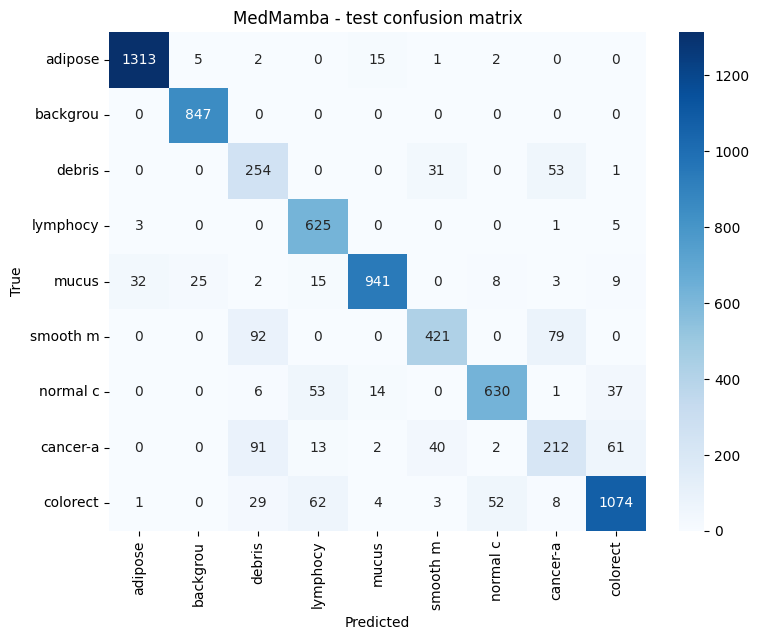


MedMamba classification report:
                                      precision    recall  f1-score   support

                             adipose       0.97      0.98      0.98      1338
                          background       0.97      1.00      0.98       847
                              debris       0.53      0.75      0.62       339
                         lymphocytes       0.81      0.99      0.89       634
                               mucus       0.96      0.91      0.94      1035
                       smooth muscle       0.85      0.71      0.77       592
                 normal colon mucosa       0.91      0.85      0.88       741
            cancer-associated stroma       0.59      0.50      0.54       421
colorectal adenocarcinoma epithelium       0.90      0.87      0.89      1233

                            accuracy                           0.88      7180
                           macro avg       0.83      0.84      0.83      7180
                        weigh

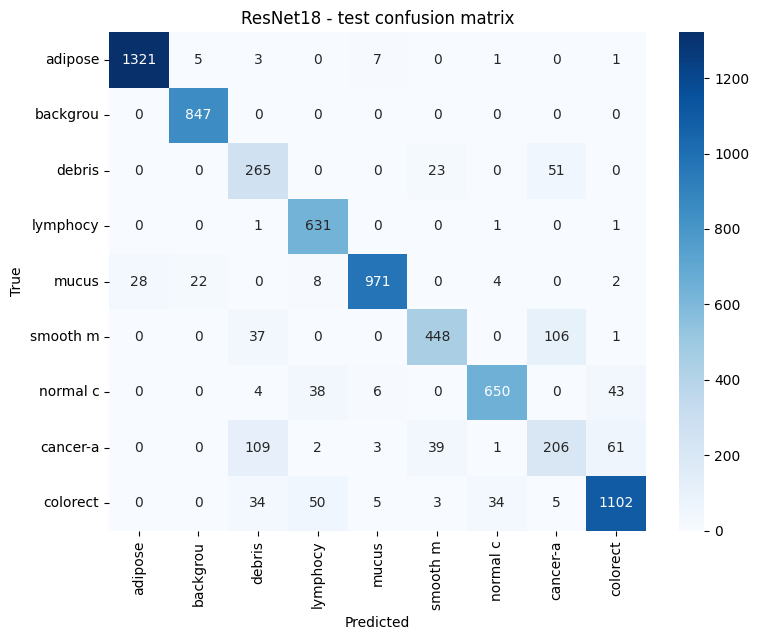


ResNet18 classification report:
                                      precision    recall  f1-score   support

                             adipose       0.98      0.99      0.98      1338
                          background       0.97      1.00      0.98       847
                              debris       0.58      0.78      0.67       339
                         lymphocytes       0.87      1.00      0.93       634
                               mucus       0.98      0.94      0.96      1035
                       smooth muscle       0.87      0.76      0.81       592
                 normal colon mucosa       0.94      0.88      0.91       741
            cancer-associated stroma       0.56      0.49      0.52       421
colorectal adenocarcinoma epithelium       0.91      0.89      0.90      1233

                            accuracy                           0.90      7180
                           macro avg       0.85      0.86      0.85      7180
                        weigh

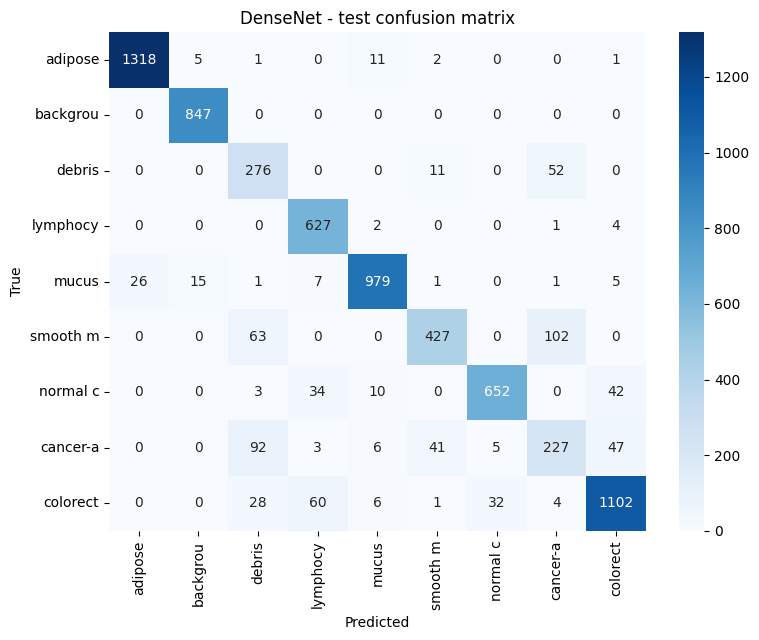


DenseNet classification report:
                                      precision    recall  f1-score   support

                             adipose       0.98      0.99      0.98      1338
                          background       0.98      1.00      0.99       847
                              debris       0.59      0.81      0.69       339
                         lymphocytes       0.86      0.99      0.92       634
                               mucus       0.97      0.95      0.96      1035
                       smooth muscle       0.88      0.72      0.79       592
                 normal colon mucosa       0.95      0.88      0.91       741
            cancer-associated stroma       0.59      0.54      0.56       421
colorectal adenocarcinoma epithelium       0.92      0.89      0.91      1233

                            accuracy                           0.90      7180
                           macro avg       0.86      0.86      0.86      7180
                        weigh

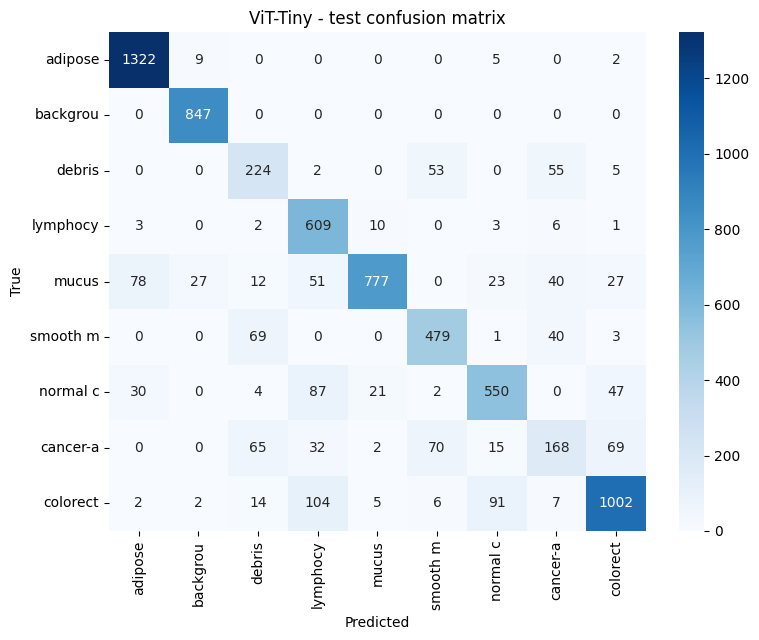


ViT-Tiny classification report:
                                      precision    recall  f1-score   support

                             adipose       0.92      0.99      0.95      1338
                          background       0.96      1.00      0.98       847
                              debris       0.57      0.66      0.61       339
                         lymphocytes       0.69      0.96      0.80       634
                               mucus       0.95      0.75      0.84      1035
                       smooth muscle       0.79      0.81      0.80       592
                 normal colon mucosa       0.80      0.74      0.77       741
            cancer-associated stroma       0.53      0.40      0.46       421
colorectal adenocarcinoma epithelium       0.87      0.81      0.84      1233

                            accuracy                           0.83      7180
                           macro avg       0.79      0.79      0.78      7180
                        weigh

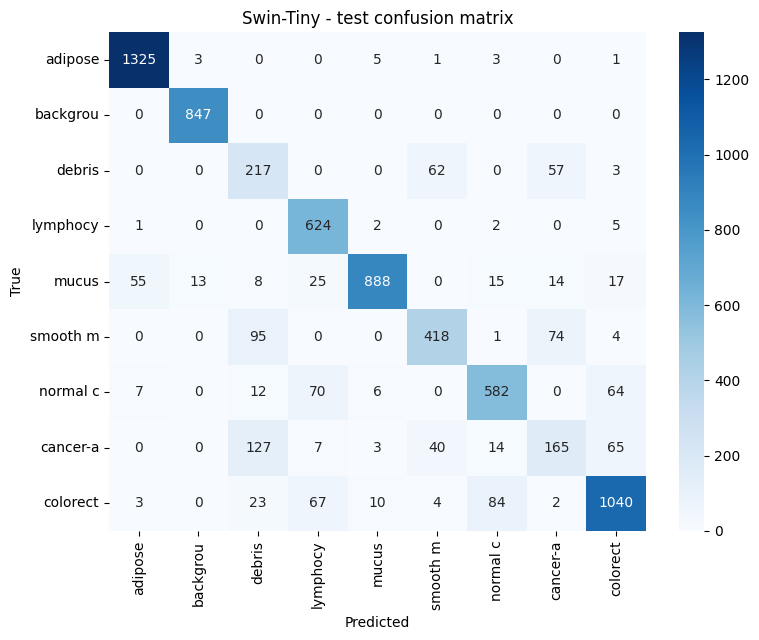


Swin-Tiny classification report:
                                      precision    recall  f1-score   support

                             adipose       0.95      0.99      0.97      1338
                          background       0.98      1.00      0.99       847
                              debris       0.45      0.64      0.53       339
                         lymphocytes       0.79      0.98      0.87       634
                               mucus       0.97      0.86      0.91      1035
                       smooth muscle       0.80      0.71      0.75       592
                 normal colon mucosa       0.83      0.79      0.81       741
            cancer-associated stroma       0.53      0.39      0.45       421
colorectal adenocarcinoma epithelium       0.87      0.84      0.86      1233

                            accuracy                           0.85      7180
                           macro avg       0.80      0.80      0.79      7180
                        weig

In [12]:
for name, (y_true, y_pred) in test_predictions.items():
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=[c[:8] for c in class_names], yticklabels=[c[:8] for c in class_names])
    plt.title(f"{name} - test confusion matrix")
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{name}_confusion_matrix.png"), dpi=200)
    plt.show()

    report = classification_report(y_true, y_pred, target_names=class_names, zero_division=0)
    print(f"\n{name} classification report:\n{report}")
    with open(os.path.join(OUTPUT_DIR, f"{name}_classification_report.txt"), "w") as f:
        f.write(report)

In [13]:
import shutil
zip_path = shutil.make_archive("/content/pathmnist_experiment_results", "zip", OUTPUT_DIR)
print("Results saved to:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    pass

Results saved to: /content/pathmnist_experiment_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>